Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0



Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#need to map gates to ion channels to neurons
#although if we assume 2 gates per neuron, we can just map gates to neuron 


def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

# gate1 = genGate(-40,2,10,20,-45,10)
# gate2 = genGate(-35,-2,1,10,-45,10)


#two voltage gates, a calcium gate, and a spike gate 
# channel = {"ion":"Na",
#            "Erev": 90,
#            "conductance": 10,
#            "gates":{
#            "vGate1":gate1, #typically the activation gate (negative k)
#            "vGate2":gate2, #typically inactivation gate (postivive k)
#            "CaGate":genOpenGate(),
#            "spikeGate":genOpenGate()}}

Nav1x6 = {"name":"Nav1x6",
            "ion":"Na",
           "Erev": 90,
           "conductance": 5,
           "gates":{
           "vGate1":genGate(-35,-1/6,0.05,0.05,-1000,100),
           "vGate2":genGate(-60,1/6,0.9,0.1,-1000,100),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

Kv2x1 = {"name":"Kv2x1",
        "ion":"K",
           "Erev": -90,
           "conductance": 20,
           "gates":{
           "vGate1":genGate(-20,-1/10,1,45,-46,1/44),
           "vGate2":genOpenGate(),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

Kv3x1 = {"name":"Kv3x1",
        "ion":"K",
           "Erev": -90,
           "conductance": 5,
           "gates":{
           "vGate1":genGate(-10,-1/8,1,5,-8,1/10),
           "vGate2":genOpenGate(),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

leakChannel = {"name":"leak",
            "ion":"all",
           "Erev": -75,
           "conductance": 1,
           "current":0,
           "gates":{
           "vGate1":genOpenGate(),
           "vGate2":genOpenGate(),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

allChannelData = {key:[] for key in genOpenGate().keys()}
allChannelData["neuronId"] = []
allChannelData["conductance"] = []
#allChannelData["ionIndex"] = [] #could use Erev either?
allChannelData["Erev"] = []
allChannelData["nChannels"] = 0

def addChannelToNeuron(neuronId,ionChannelInfo,allChanData):
    gates = ionChannelInfo["gates"]
    gateSubKeys = gates[list(gates.keys())[0]].keys()
    #pull out the data into a list
    data = {gsk: [gv[gsk] for gv in gates.values()] for gsk in gateSubKeys}
    for key,newData in data.items():
        allChanData[key].append(newData)
    allChannelData["neuronId"].append(neuronId)
    allChannelData["Erev"].append(ionChannelInfo["Erev"])
    allChannelData["conductance"].append(ionChannelInfo["conductance"])
    allChannelData["nChannels"]+=1
    #allChannelData["gatingValue"].append([0.0 for _ in range(4)])

nNeurons = 5
for i in range(nNeurons):
    addChannelToNeuron(i,leakChannel,allChannelData)
    addChannelToNeuron(i,Nav1x6,allChannelData)
    #addChannelToNeuron(i,Kv2x1,allChannelData)
    addChannelToNeuron(i,Kv3x1,allChannelData)


allChannelData["voltages"] = -70*np.ones(nNeurons,dtype = np.float32) +np.arange(0,nNeurons,dtype=np.float32)
allChannelData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
allChannelData["spikeVals"] = np.zeros(nNeurons,dtype = np.float32)


#allChannelData
#systemNumpyArrays = {key:np.array(val,dtype = np.float32) for key,val in allChannelData.items()}
#step one, find a convenient to get this into c++

for key in allChannelData.keys():
    val = allChannelData[key]
    if type(val) in [list,tuple]:
        if type(val[0]) == int:
            allChannelData[key] = np.array(val,dtype = np.int32)
        else:
            allChannelData[key] = np.array(val,dtype = np.float32)

    print(key)

x
vHalf
vKi
tau0
tau1
th
tkInv
neuronId
conductance
Erev
nChannels
voltages
calciumVals
spikeVals


In [2]:
allChannelData.keys()

dict_keys(['x', 'vHalf', 'vKi', 'tau0', 'tau1', 'th', 'tkInv', 'neuronId', 'conductance', 'Erev', 'nChannels', 'voltages', 'calciumVals', 'spikeVals'])

In [3]:
import os,sys
build_dir,configType = "build", "Debug"
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

cathalTest.solveNeuralSystem(allChannelData,2,0.01)

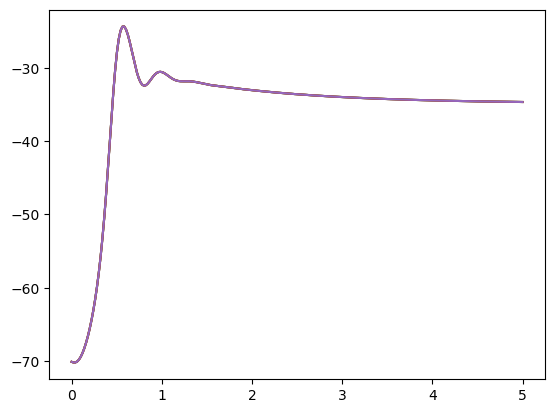

In [31]:
def sigmoid(z,h,kInv):
    return 1.0/(1.0 + np.exp((h-z)*kInv))

def solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk):
    xInf = sigmoid(s,xh,xk)#*(xt0+xt1)/TS
    tau = xt0 + xt1*sigmoid(s,xth,xtk)
    return x + TS*(xInf-x)/tau
    #return (tau*x + TS*xInf)/(tau+TS)

def solveSystemStandard(nNeurons,ac,TS,runTime):
    voltage = -70*np.ones([nNeurons],dtype = np.float32)
    calciumVals = np.zeros([nNeurons],dtype = np.float32)
    spikeVals = np.zeros([nNeurons],dtype = np.float32)
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    vOverTime = []
    nChannels = len(ac["neuronId"])
    for iteration,t in enumerate(tv):   
        #calculate currents
        netCurrent = np.zeros([nNeurons])
        # for i in range(nChannels):
        #     neurId = ac["neuronId"][i]
        #     V = voltage[neurId]
        #     xs = ac["x"][i]
        #     Erev = ac["Erev"][i]
        #     g = ac["conductance"][i]

        #     gatingTotal = 1
        #     for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
        #     I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
        #     netCurrent[neurId] += I
        #     voltage[neurId] += TS*I #cm = 1   

        #update the gates
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]
            tempTS = TS
            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            netCurrent[neurId] += I

            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate

        for i in range(nNeurons):
            voltage[i] += TS*netCurrent[i]
            


        vOverTime.append(voltage.copy())
    return np.array(vOverTime)


from copy import deepcopy

TS = 0.02
runTime = 5
vData2 = solveSystemStandard(nNeurons,deepcopy(allChannelData),TS,runTime)

tv = np.linspace(0,runTime,len(vData2))
plt.plot(tv,vData2);

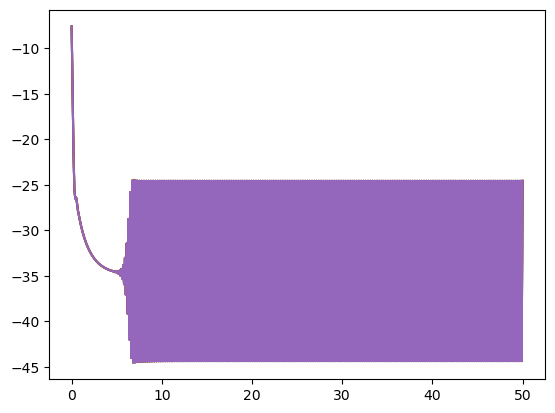

In [132]:
#thought I could be clever about it, but its hard to beat the basic solver.
def solveSystemStrangSplit(nNeurons,ac,TS,runTime):
    voltage = np.zeros([nNeurons],dtype = np.float32)
    calciumVals = np.zeros([nNeurons],dtype = np.float32)
    spikeVals = np.zeros([nNeurons],dtype = np.float32)
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    vOverTime = []
    nChannels = len(ac["neuronId"])
    for iteration,t in enumerate(tv):   
        #solve gates for a half step 
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            tempTS = TS/2
            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate
        

        #calculate currents
        netCurrent = np.zeros([nNeurons])
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            xs = ac["x"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]

            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            #ac["current"][i] = I
            netCurrent[neurId] += I


        #calculate the voltage
        for i in range(nNeurons):
            voltage[i] = voltage[i] + TS*netCurrent[i] #assume membrane capacitance is 1

        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            tempTS = TS/2
            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate


        vOverTime.append(voltage.copy())
        
    return np.array(vOverTime)

TS = 0.1
runTime = 50
vData = solveSystemStrangSplit(nNeurons,deepcopy(allChannelData),TS,runTime)

tv = np.linspace(0,runTime,len(vData))
plt.plot(tv,vData);

In [ ]:
def solveSystemStandard(nNeurons,ac,TS,runTime):
    voltage = -70*np.ones([nNeurons],dtype = np.float32)
    calciumVals = np.zeros([nNeurons],dtype = np.float32)
    spikeVals = np.zeros([nNeurons],dtype = np.float32)
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    vOverTime = []
    nChannels = len(ac["neuronId"])
    for iteration,t in enumerate(tv):   
        #calculate currents
        netCurrent = np.zeros([nNeurons])
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            xs = ac["x"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]

            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            netCurrent[neurId] += I
            voltage[neurId] += TS*I #cm = 1

        #update the gates
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            tempTS = TS
            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate

        vOverTime.append(voltage.copy())
    return np.array(vOverTime)

In [135]:


#calculate currents
#I = g*vGate1*vGate2*CaGate*spikeGate*(V-Erev)

voltage = np.zeros([nNeurons])
calciumVals = np.zeros([nNeurons])
spikeVals = np.zeros([nNeurons])


ac = allChannelData
nChannels = ac["nChannels"]

# netGating = ac["x"][0][0]*ac["x"][0][1]*ac["x"][0][2]*ac["x"][0][3]
# neurId = 0
# I = ac["conductance"][0]*netGating*(V[neurId]-ac["Erev"][0])

#dont forget that cool solving method 

#solve gates -> calculate currents -> calculate voltage
#going to do it with plain euler first
#then semi-implicit euler
#then strang splitting

#TS>0.17 = unstable
TS = 0.05
runTime = 20

nIterations = int(runTime/TS)
tv = np.linspace(0,runTime,nIterations)
vOverTime = []

def solveSystemStandard():
    for iteration,t in enumerate(tv):   
        #calculate currents
        netCurrent = np.zeros([nNeurons])
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            xs = ac["x"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]

            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            # if i == 0:
            #     print((V-Erev))
            #ac["current"][i] = I
            netCurrent[neurId] += I


        #calculate the voltage
        for i in range(nNeurons):
            voltage[i] = voltage[i] + TS*netCurrent[i]

        #update the gates
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            xDot = [0.0 for _ in range(4)]
            #gate1
            xs[0] = solveGate(xs[0],V,TS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0])
            #gate2
            xs[1] = solveGate(xs[1],V,TS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1])
            #CaGate
            xs[2] = solveGate(xs[2],Ca,TS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2])
            #spikeGate
            xs[3] = solveGate(xs[3],spikes,TS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3])

        
        vOverTime.append(voltage.copy())
    return np.array(vOverTime)
# plt.plot(tv,vOverTime);

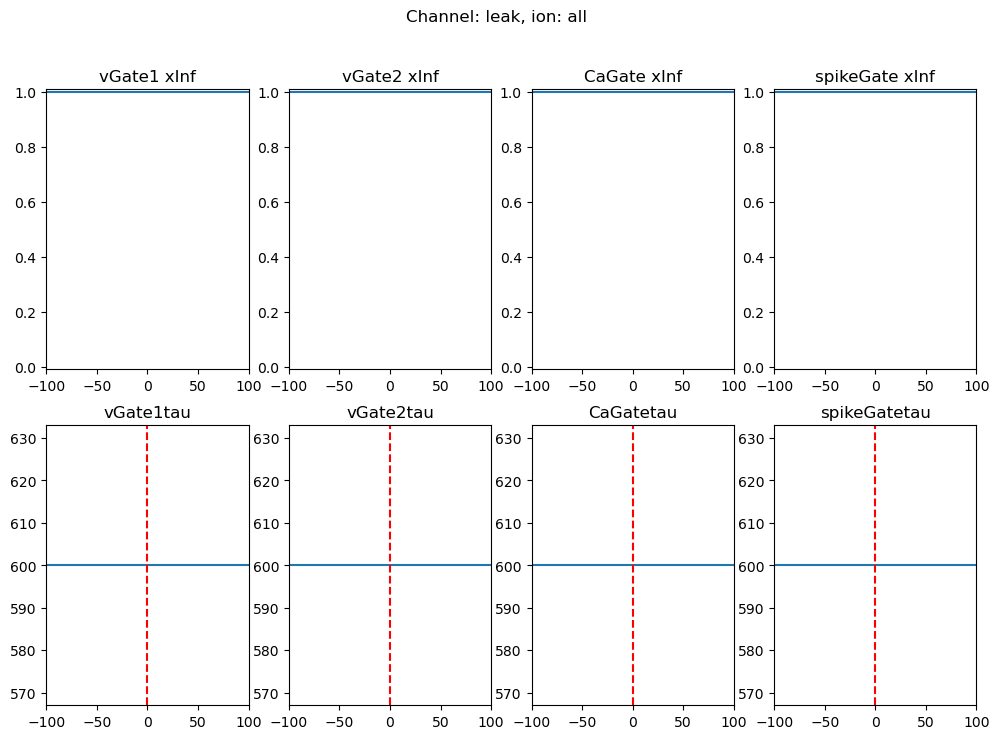

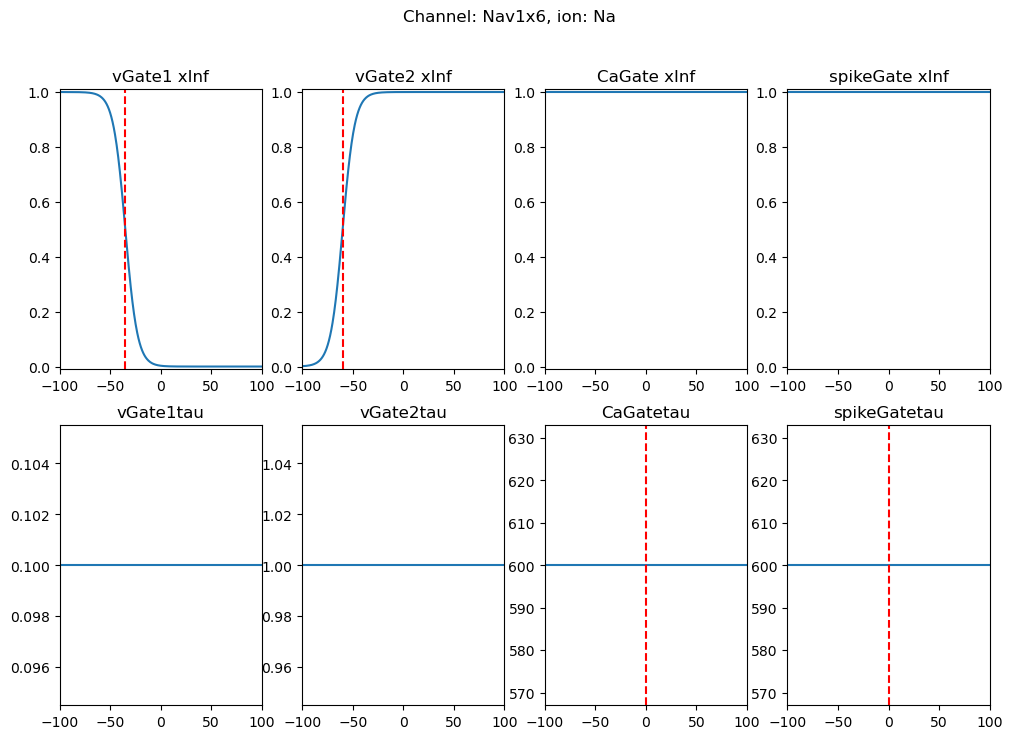

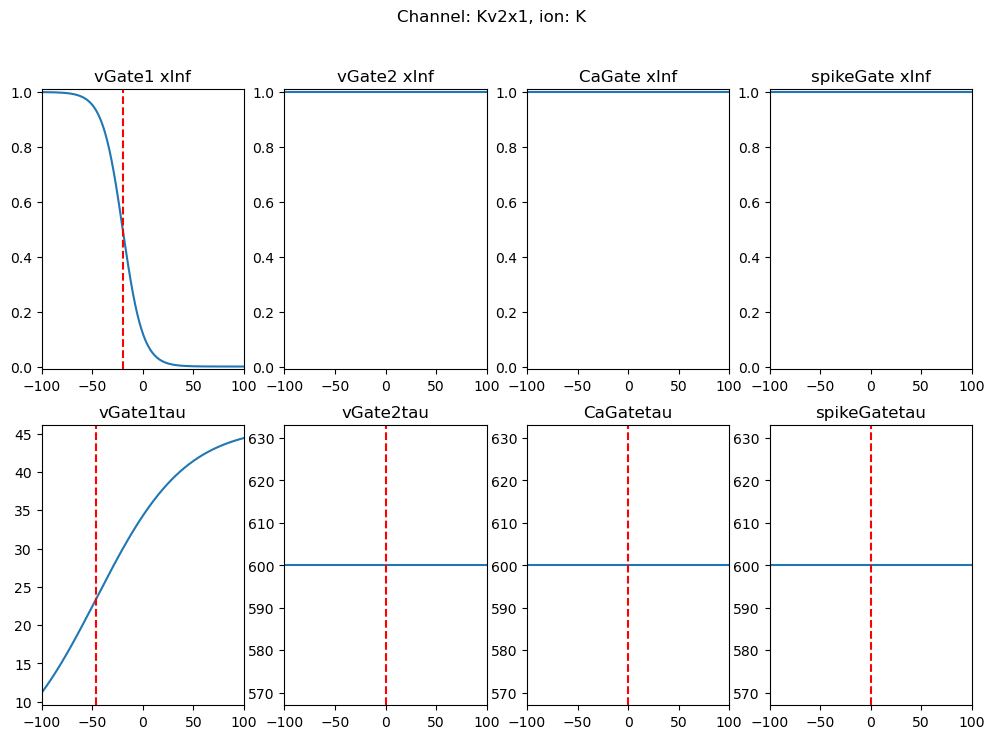

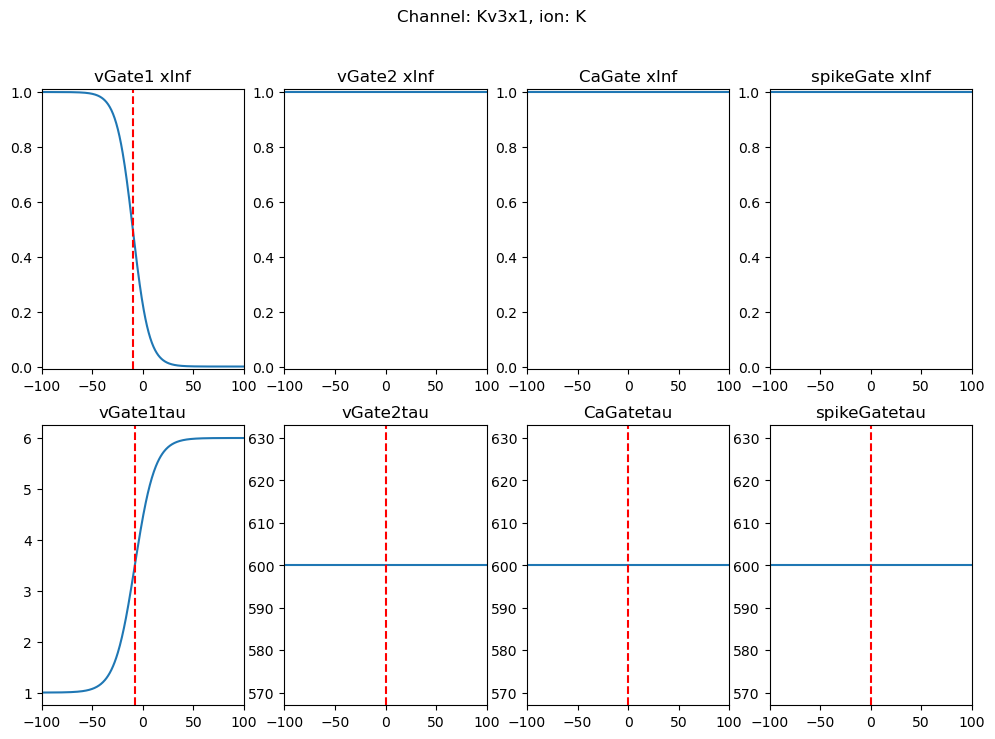

In [136]:

def examineGate(gateInfo,gRange,gateName,ax=None):
    sps = np.linspace(gRange[0],gRange[1],501)
    vH,vK = gateInfo["vHalf"],gateInfo["vKi"]
    tau0,tau1,th,tkInv = gateInfo["tau0"],gateInfo["tau1"],gateInfo["th"],gateInfo["tkInv"]

    xInf = sigmoid(sps,vH,vK)
    tau = tau0 + tau1*sigmoid(sps,th,tkInv)
    if ax == None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    else:
        ax[0].plot(sps,xInf)
        ax[0].axvline(vH,color="r",linestyle="--")
        ax[0].set_title(f"{gateName} xInf")
        ax[0].set_xlim(gRange)
        #x[0].set_ylabel("Gate opening")
        ax[0].set_ylim(-0.01,1.01)

        ax[1].plot(sps,tau)
        ax[1].axvline(th,color="r",linestyle="--")
        ax[1].set_title(f"{gateName}tau")
        #ax[1].set_ylabel("Time constant (ms)")
        ax[1].set_xlim(gRange)
        

def examineChannel(channel):
    fig,ax = plt.subplots(2,4,figsize=(12,8), dpi=100)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        examineGate(gateData,[-100,100],gate,[ax[0,i],ax[1,i]])

examineChannel(leakChannel)
examineChannel(Nav1x6)
examineChannel(Kv2x1)
examineChannel(Kv3x1)

In [75]:

def solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk):
    xInf = sigmoid(s,xh,xk)#*(xt0+xt1)/TS
    tau = xt0 + xt1*sigmoid(s,xth,xtk)
    return (tau*x + TS*xInf)/(tau+TS)





def runGateSim(xt0,xt1,TS):
    #TS = 0.02
    x = 0
    xh = 0.5
    xk = 100.0
    xt0 = TS/1000
    xt1 = xt1-xt0
    xth = 0.5
    xtk = -100.0
    runTime = 40
    
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    xOverTime = []
    for i in range(nIterations):
        s = 0
        if i == int(5/TS):
            s = 1
        x = solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk)
        xOverTime.append(x)

    fig,ax = plt.subplots(1,1,figsize=(8,6), dpi=100, sharex=True)
    ax.plot(tv,xOverTime)

from ipywidgets import interact
interact(runGateSim,xt0=(0.01,1.0,0.01),xt1=(0.1,10.0,0.1),TS=(0.01,0.1,0.01))

interactive(children=(FloatSlider(value=0.5, description='xt0', max=1.0, min=0.01, step=0.01), FloatSlider(val…

<function __main__.runGateSim(xt0, xt1, TS)>

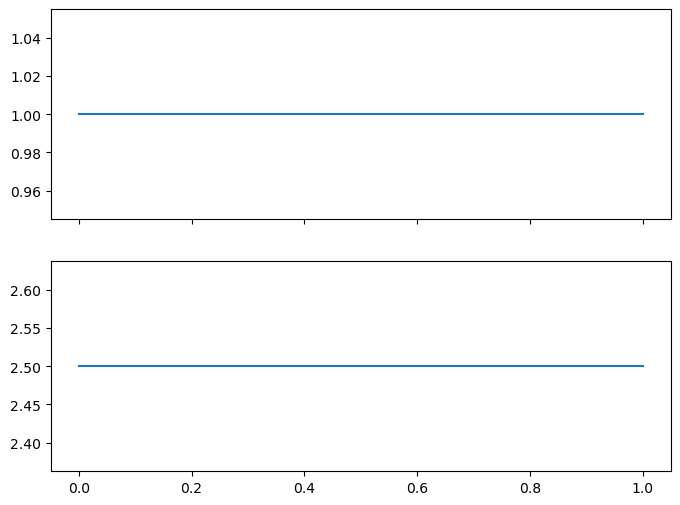

In [83]:
#test the gates quickly
TS = 0.02
xh = -0.5
xk = 100.0
xt0 = TS/1000
xt1 = 5
xth = -0.5
xtk = 0

sps = np.linspace(0,1,100)
xInf = sigmoid(sps,xh,xk)
tau = xt0 + xt1*sigmoid(sps,xth,xtk)

fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100, sharex=True)
ax[0].plot(sps,xInf)
ax[1].plot(sps,tau)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])